In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backprop = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad}, _op={self._op}, _children={self._prev})"

    def __add__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backprop():
            self.grad += out.grad
            other.grad += out.grad

        out._backprop = _backprop
        return out
    
    def radd(self, other):
            return self + other

    def pow(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data ** other, (self, ), f'**{other}')

        def _backprop(self, other):
            self.grad += other * (self.data ** (other-1)) * out.grad
            
        out._backprop = _backprop
        return out
    
    def __truediv__(self, other):
        return self * other**-1
    
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backprop():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backprop = _backprop
        return out
    
    #Porque al entrar en esta función al estar desordenadas se ordenan solas es decir: 1 * b => rmul(1, b) b(Value) siempre es el self
    def rmul(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other) 

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), 'tanh')

        def _backprop():
            self.grad += (1 - t**2) * out.grad

        out._backprop = _backprop
        return out

    def exp(self):
        x = self.data
        out =  Value(math.exp(x), (self, ), 'exp')

        def _backprop():
            self.grad += out.data * out.grad

        out._backprop = _backprop
        return out
    
    def backward(self):
        topo = []
        visited = set()

        def build_topo(value):
            if value not in visited:
                visited.add(value)
                for child in value._prev:
                    build_topo(child)
                topo.append(value)

        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backprop()

    backprop = backward


a = Value(2.0)
b = Value(3.0)
c = a + b
e = Value(4.0)
d = c * e
d

# D tiene gradiente 1 porque la derivada parcial de d respecto de d es 1.

Value(data=20.0, grad=0.0, _op=*, _children={Value(data=4.0, grad=0.0, _op=, _children=set()), Value(data=5.0, grad=0.0, _op=+, _children={Value(data=3.0, grad=0.0, _op=, _children=set()), Value(data=2.0, grad=0.0, _op=, _children=set())})})

In [24]:
%pip install graphviz
import os
from graphviz import Digraph

os.environ['PATH'] += os.pathsep + r'C:\Program Files\Graphviz\bin'


def trace(root):
    """Construye un conjunto de todos los nodos y enlaces del grafo."""
    nodes, edges = set(), set()

    def build(value):
        if value in nodes:
            return
        nodes.add(value)
        for child in value._prev:
            edges.add((child, value))
            build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    """Genera el diagrama visual con Graphviz."""
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for node in nodes:
        uid = str(id(node))
        dot.node(
            name=uid,
            label=f'{{ {node.label} | data {node.data:.4f} | grad {node.grad:.4f} }}',
            shape='record',
        )

        if node._op:
            dot.node(name=uid + node._op, label=node._op)
            dot.edge(uid + node._op, uid)

    for source, target in edges:
        dot.edge(str(id(source)), str(id(target)) + target._op)

    return dot

Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at c:\programacion\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


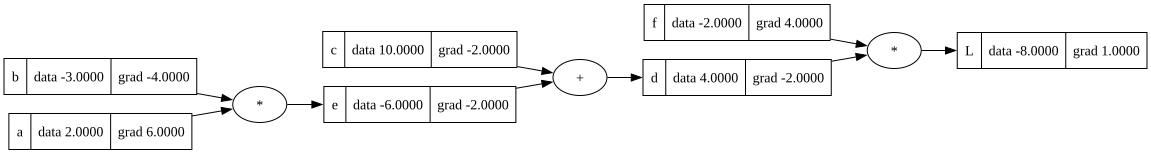

In [ ]:
# Definimos la red / expresión matemática con etiquetas
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b
e.label = 'e'
d = e + c
d.label = 'd'
f = Value(-2.0, label='f')
L = d * f
L.label = 'L'

# Ejecutamos el backward pass
L.backward()

# Visualizamos el diagrama
draw_dot(L)

In [ ]:
import random

class Neuron:
    def __init__(self, nin):
        """nin -> Number of inputs in the neuron so that you can create an equal amount of weights"""
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))            

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out